# ISYE 4031 Group 9: Milestone 2
Bill Nguyen, Sarah Wang, Cindy Le, Phoenix Moore, Victor Wang.

**Question:** After the initial earnings reaction, can available information predict
the signed stock return over the following five trading sessions?

Prediction is at the close of the first stock trading day strictly after the
reported date. The raw signed return is primary; SPY-adjusted return is secondary.
The reaction-day jump is excluded, and negative outcomes are retained. This
notebook uses actual cached observations. Run `run_pipeline.py` first.

Prepared with Codex assistance using the existing cached snapshot. Individual
Milestone 2 work and proposed task assignments must be confirmed before submission.


In [1]:
from pathlib import Path
import contextlib
import io
import json
import sys
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / 'run_milestone2.py').exists():
    ROOT = ROOT.parent
assert (ROOT / 'run_milestone2.py').exists(), 'Open from project root or notebooks/'
sys.path.insert(0, str(ROOT))
import run_milestone2
with contextlib.redirect_stdout(io.StringIO()):
    run_milestone2.main()
OUT = ROOT / 'outputs/milestone2'
FIG = ROOT / 'figures/milestone2'
summary = json.loads((OUT / 'analysis_summary.json').read_text())
print('All Milestone 2 outputs rebuilt from processed data; source formulas checked.')
print('Python used:', summary['python'])


All Milestone 2 outputs rebuilt from processed data; source formulas checked.
Python used: 3.12.7


## Data pipeline and quality
EARNINGS JSON -> parsed event dates and numbers -> restrict 2016-2025 ->
first-later-session match -> historical predictors and stock/SPY targets ->
all-events table and complete-case modeling table. No missing financial values
are imputed. Outside-window records are excluded; genuine extremes are retained.
Price caches cover 2015-11-02 to 2026-01-30 for each symbol.

All 400 event dates, earnings values, historical price/volume features and targets
are independently recalculated by the script, with an assertion on agreement.
This checks mechanics, not point-in-time availability of vendor values.


In [2]:
display(pd.read_csv(OUT / 'data_quality.csv'))
display(pd.read_csv(OUT / 'price_quality.csv'))
display(pd.read_csv(OUT / 'missingness.csv'))
display(pd.read_csv(OUT / 'formula_checks.csv'))


,metric,value
0,raw_records,1.105000e+03
1,exact_raw_duplicates,0.000000e+00
2,invalid_reported_dates,0.000000e+00
3,outside_event_window,7.050000e+02
4,in_window_events,4.000000e+02
5,modeling_events,4.000000e+02
6,duplicate_event_keys,0.000000e+00
7,missing_required_predictor_cells,0.000000e+00
8,nonfinite_modeling_values,0.000000e+00
9,invalid_timing_rows,0.000000e+00


,ticker,rows,duplicate_dates,invalid_dates,missing_close,missing_adjusted_close,missing_volume,nonpositive_close,negative_volume,nonfinite_values,first_date,last_date
0,AAPL,2576,0,0,0,0,0,0,0,0,2015-11-02,2026-01-30
1,MSFT,2576,0,0,0,0,0,0,0,0,2015-11-02,2026-01-30
2,NVDA,2576,0,0,0,0,0,0,0,0,2015-11-02,2026-01-30
3,AMZN,2576,0,0,0,0,0,0,0,0,2015-11-02,2026-01-30
4,META,2576,0,0,0,0,0,0,0,0,2015-11-02,2026-01-30
5,GOOGL,2576,0,0,0,0,0,0,0,0,2015-11-02,2026-01-30
6,JPM,2576,0,0,0,0,0,0,0,0,2015-11-02,2026-01-30
7,XOM,2576,0,0,0,0,0,0,0,0,2015-11-02,2026-01-30
8,JNJ,2576,0,0,0,0,0,0,0,0,2015-11-02,2026-01-30
9,WMT,2576,0,0,0,0,0,0,0,0,2015-11-02,2026-01-30


,variable,missing_count,missing_percent
0,reported_date,0,0.0
1,reaction_day,0,0.0
2,prediction_start_date,0,0.0
3,prediction_end_date,0,0.0
4,earnings_surprise_pct,0,0.0
5,reported_eps,0,0.0
6,estimated_eps,0,0.0
7,earnings_surprise,0,0.0
8,reaction_day_return,0,0.0
9,abnormal_volume,0,0.0


,variable,max_absolute_error,events_checked
0,earnings_surprise_pct,0.000000e+00,400
1,reported_eps,0.000000e+00,400
2,estimated_eps,0.000000e+00,400
3,earnings_surprise,0.000000e+00,400
4,reaction_day_return,9.887924e-17,400
5,abnormal_volume,4.440892e-16,400
6,return_5d_before,9.714451e-17,400
7,return_20d_before,9.887924e-17,400
8,volatility_20d,9.974660e-17,400
9,spy_return_5d_before,9.974660e-17,400


## Exploratory findings
All 400 events remain in the figures, including surprise tails. 223 returns are
positive (55.75%), 177 are negative, and none is zero. Mean +0.242%, median
+0.319%, SD 4.085 pp. The reaction-day relationship is modest (r=0.187); surprise
is weaker (r=0.045). Descriptive fitted lines are full-sample exploration and do
not set the held-out model. Associations do not establish causation.


,count,mean,std,min,25%,50%,75%,max
earnings_surprise_pct,400.0,12.907592,70.159355,-266.666700,1.573250,6.900850,15.582025,960.000000
reported_eps,400.0,1.494095,1.341389,-0.700000,0.475000,1.235000,2.155000,8.020000
estimated_eps,400.0,1.388529,1.194999,-0.600000,0.463250,1.190000,2.040000,6.710000
earnings_surprise,400.0,0.105566,0.287742,-1.540000,0.010000,0.060000,0.190000,1.530000
reaction_day_return,400.0,0.005391,0.057061,-0.263901,-0.019985,0.000035,0.028847,0.298067
abnormal_volume,400.0,2.124396,1.128741,0.674214,1.316472,1.892846,2.581343,9.323869
return_5d_before,400.0,0.008944,0.040344,-0.127083,-0.015377,0.008132,0.032949,0.154907
return_20d_before,400.0,0.030520,0.075822,-0.238885,-0.012619,0.032791,0.068420,0.326169
volatility_20d,400.0,0.016451,0.008707,0.002926,0.010217,0.014349,0.020433,0.059887
spy_return_5d_before,400.0,0.004203,0.021934,-0.085056,-0.006115,0.003904,0.014402,0.082843


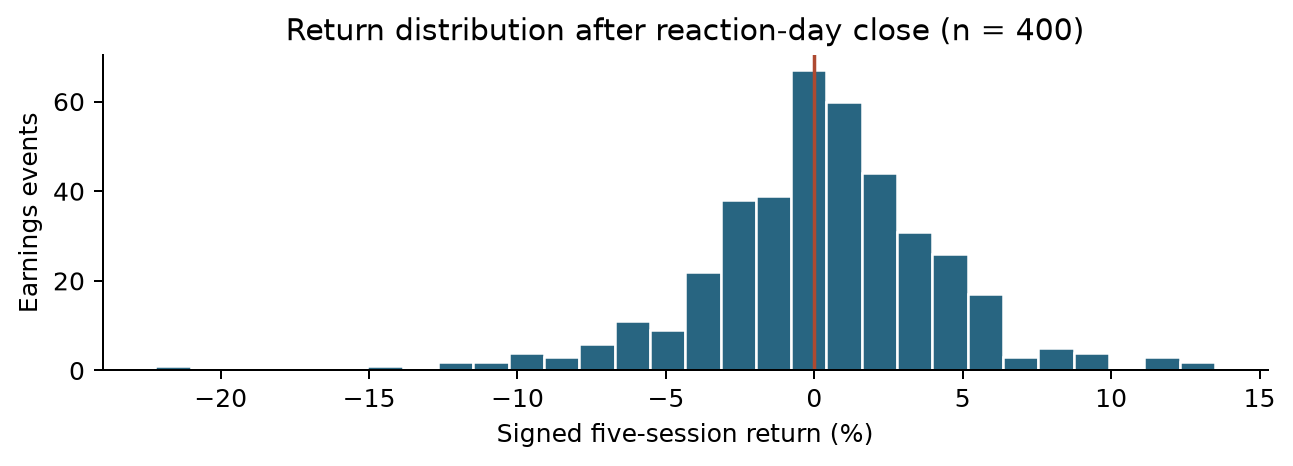

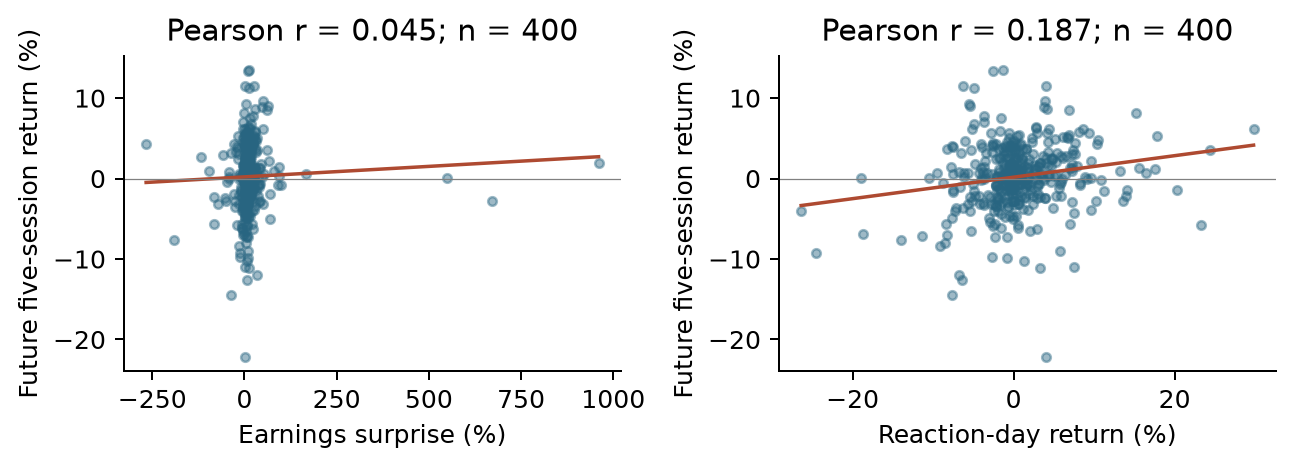

,year,n,mean_return,sd_return,positive_share
0,2016,40,-0.002644,0.042758,0.525
1,2017,40,0.004226,0.022966,0.625
2,2018,40,-0.008808,0.039442,0.400
3,2019,40,-0.002291,0.030970,0.525
4,2020,40,0.023269,0.040437,0.675
5,2021,40,0.006008,0.043411,0.550
6,2022,40,-0.008987,0.059606,0.525
7,2023,40,-0.002147,0.036736,0.425
8,2024,40,0.010124,0.034328,0.725
9,2025,40,0.005451,0.041687,0.600


,ticker,n,mean_return,sd_return,positive_share
0,AAPL,40,0.009138,0.044059,0.550
1,AMZN,40,-0.001778,0.047719,0.625
2,GOOGL,40,-0.006918,0.040468,0.475
3,JNJ,40,0.003139,0.022429,0.550
4,JPM,40,0.006208,0.025820,0.625
5,META,40,0.002562,0.042471,0.550
6,MSFT,40,0.003375,0.039239,0.650
7,NVDA,40,-0.001026,0.068821,0.500
8,WMT,40,0.001171,0.025785,0.500
9,XOM,40,0.008331,0.032935,0.550


In [3]:
display(pd.read_csv(OUT / 'descriptive_statistics.csv', index_col=0))
display(Image(filename=str(FIG / '01_return_distribution.png')))
display(Image(filename=str(FIG / '02_predictor_relationships.png')))
display(pd.read_csv(OUT / 'year_summary.csv'))
display(pd.read_csv(OUT / 'ticker_summary.csv'))


## Simple baseline and chronological evaluation
OLS uses an intercept and 10 predictors. Dollar earnings surprise is omitted
because it is exactly reported minus estimated EPS. The data retain that variable.
StandardScaler fits on training only. The model is fixed using 2016-2022 (n=280),
validation is 2023-2024 (n=80), and the exploratory test is 2025 (n=40).
Boundary-crossing target windows are purged from the earlier period; none occur
in this snapshot. No random split, tuning, or validation refitting is used.

Training-mean and zero forecasts provide references. MAE and RMSE are in
percentage points; R2 uses the evaluation-period mean as its denominator.
`mse_skill_vs_training_mean` compares squared error with the training reference.
Zero has no positive direction predictions; sign accuracy treats zero as nonpositive.


In [4]:
print('Model predictors:', summary['model_features'])
display(pd.read_csv(OUT / 'split_summary.csv'))
metrics = pd.read_csv(OUT / 'baseline_metrics.csv')
display(metrics.loc[metrics['split'] != 'train'].round(4))
display(pd.read_csv(OUT / 'coefficients.csv').round(4))


Model predictors: ['earnings_surprise_pct', 'reported_eps', 'estimated_eps', 'reaction_day_return', 'abnormal_volume', 'return_5d_before', 'return_20d_before', 'volatility_20d', 'spy_return_5d_before', 'previous_earnings_surprise_pct']


,split,n,first_reaction,last_reaction,last_target_end
0,train,280,2016-01-15,2022-11-17,2022-11-25
1,validation,80,2023-01-17,2024-11-21,2024-11-29
2,test,40,2025-01-16,2025-11-21,2025-12-01


,target,split,model,n,mae_pp,rmse_pp,r2,mse_skill_vs_training_mean,mean_error_pp,direction_accuracy
3,future_5d_return,validation,OLS,80,2.9059,3.8375,-0.1596,-0.1541,-0.4343,0.5750
4,future_5d_return,validation,Training mean,80,2.6622,3.5721,-0.0047,0.0000,0.2450,0.5750
5,future_5d_return,validation,Zero,80,2.6778,3.5859,-0.0125,-0.0078,0.3989,0.4250
6,future_5d_return,test,OLS,40,3.3160,4.2535,-0.0678,-0.0582,0.2168,0.5500
7,future_5d_return,test,Training mean,40,3.1607,4.1349,-0.0090,0.0000,0.3912,0.6000
8,future_5d_return,test,Zero,40,3.1877,4.1522,-0.0175,-0.0084,0.5451,0.4000
12,market_adjusted_5d_return,validation,OLS,80,2.3810,3.0848,-0.1993,-0.1984,-0.5710,0.5375
13,market_adjusted_5d_return,validation,Training mean,80,2.0986,2.8179,-0.0007,0.0000,-0.0748,0.4875
14,market_adjusted_5d_return,validation,Zero,80,2.0860,2.8316,-0.0105,-0.0098,-0.2882,0.4875
15,market_adjusted_5d_return,test,OLS,40,2.8762,3.6055,0.0177,0.0246,0.2995,0.5500


,target,feature,coefficient_pp_per_training_sd
0,future_5d_return,earnings_surprise_pct,0.0642
1,future_5d_return,reported_eps,-0.6205
2,future_5d_return,estimated_eps,0.9095
3,future_5d_return,reaction_day_return,1.0088
4,future_5d_return,abnormal_volume,-0.1348
5,future_5d_return,return_5d_before,0.0990
6,future_5d_return,return_20d_before,0.4970
7,future_5d_return,volatility_20d,0.2105
8,future_5d_return,spy_return_5d_before,-0.8745
9,future_5d_return,previous_earnings_surprise_pct,0.3267


## Residuals and influential observations
The raw baseline is worse than the training mean in both held-out periods.
SPY-adjusted OLS is worse in validation and marginally better in 2025. This does
not establish robust predictive usefulness. Direction accuracy also does not
improve consistently on always forecasting a positive raw return.

The training design has full rank (11 columns including the intercept). Cook's
distance >4/n is an influence screen; flagged events remain in the data. The raw
model flags 17 training events. AMZN 2022-04-28 is most influential (D=0.191).
Held-out errors include AAPL 2025-07-31: +13.326% observed vs -0.649% predicted.
The residual plot shows large errors and time clusters; it does not verify
independence, constant variance or causality.


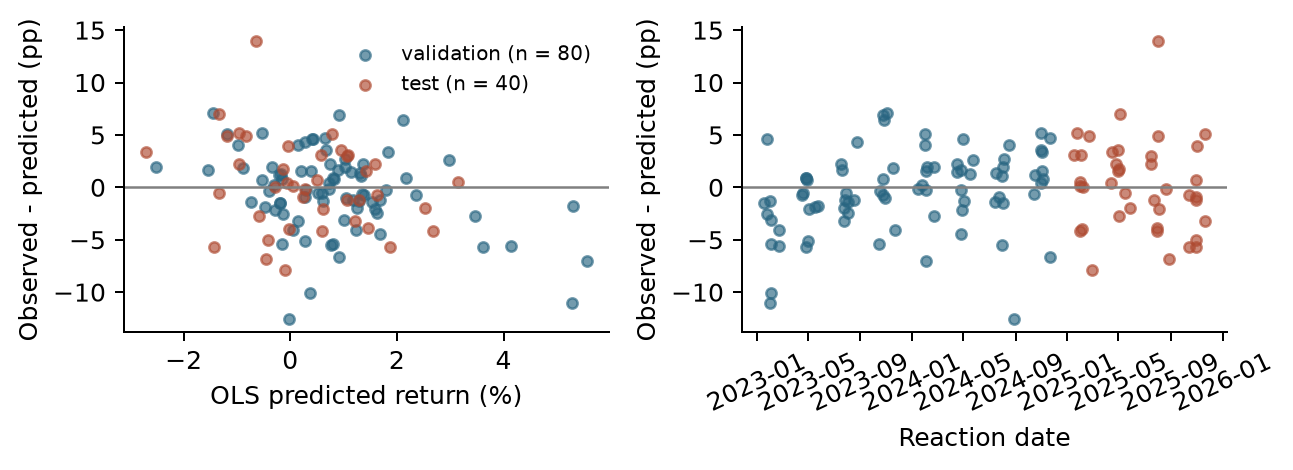

,ticker,reported_date,target,leverage,standardized_residual,cooks_distance
256,AMZN,2022-04-28,future_5d_return,0.2858,-2.2906,0.1908
269,NVDA,2022-08-24,future_5d_return,0.0370,-5.9426,0.1234
4,AMZN,2016-01-28,future_5d_return,0.0924,-3.3641,0.1048
187,XOM,2020-07-31,future_5d_return,0.5032,0.9744,0.0874
219,NVDA,2021-05-26,future_5d_return,0.0507,3.5717,0.0619
194,AMZN,2020-10-29,future_5d_return,0.1740,1.7032,0.0556
276,AMZN,2022-10-27,future_5d_return,0.1136,-2.0002,0.0466
196,META,2020-10-29,future_5d_return,0.0586,2.5772,0.0376
18,NVDA,2016-05-12,future_5d_return,0.0975,1.7647,0.0306
264,META,2022-07-27,future_5d_return,0.0860,1.6411,0.0230


,design_rank,design_columns,scaled_design_condition_number,high_leverage_count,cooks_above_4_over_n,largest_cooks_ticker,largest_cooks_date,largest_cooks_distance,training_mean
future_5d_return,11,11,10.851985,28,17,AMZN,2022-04-28,0.19085,0.001539
market_adjusted_5d_return,11,11,10.851985,28,18,AMZN,2022-04-28,0.164932,-0.002134


In [5]:
display(Image(filename=str(FIG / '03_holdout_residuals.png')))
influence = pd.read_csv(OUT / 'training_influence.csv')
display(influence.loc[influence['target'] == 'future_5d_return']
        .sort_values('cooks_distance', ascending=False).head(10).round(4))
display(pd.DataFrame(summary['diagnostics']).T)


## Meeting 2 diagnostics and the response to Meeting 1
The TA asked for longer histories per company, large-surprise and influential
event checks, sensitivity to outlier treatment, and a more informative dataset.
The primary baseline and 400 observations are preserved. All sensitivity
variants use training-only cutoffs and score all 80 validation and 40 test events.
No held-out outcomes are clipped or selectively removed. See
`reports/MEETING1_FEEDBACK.md` for the action record.


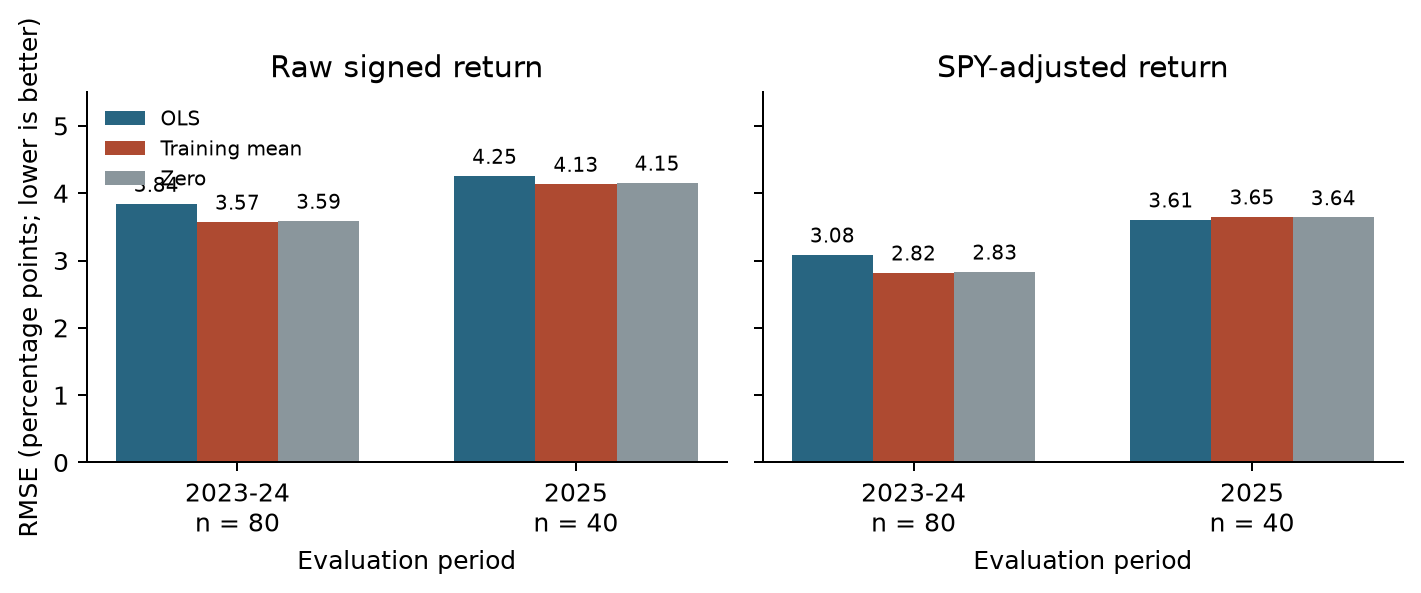

,target,split,n,mean_error_pp,median_error_pp,residual_p05_pp,residual_p95_pp,max_absolute_error_pp,absolute_error_over_5pp_count,absolute_error_over_5pp_share,predicted_min_pct,predicted_max_pct,observed_min_pct,observed_max_pct
0,future_5d_return,test,40,0.2168,0.1076,-5.7579,5.3019,13.9750,9,0.225,-2.7127,3.1450,-7.9734,13.3264
1,future_5d_return,validation,80,-0.4343,-0.3052,-6.6726,5.0742,12.5233,16,0.200,-2.5115,5.5680,-12.5521,8.5017
2,market_adjusted_5d_return,test,40,0.2995,0.6518,-5.0155,5.2326,11.5182,5,0.125,-1.5288,2.2205,-7.0398,10.8398
3,market_adjusted_5d_return,validation,80,-0.5710,-0.0823,-7.2081,3.9936,8.3937,8,0.100,-2.4244,4.9311,-9.3301,5.3524


,ticker,reported_date,estimated_eps,reported_eps,earnings_surprise_pct,future_5d_return,split
0,AMZN,2018-04-26,0.06,0.16,166.6667,0.005297,train
1,XOM,2020-05-01,0.05,0.53,960.0000,0.019162,train
2,AMZN,2020-07-30,0.08,0.52,550.0000,0.000878,train
3,AMZN,2022-02-03,0.18,1.39,672.2222,-0.027569,train
4,AMZN,2022-04-28,0.42,-0.38,-190.4762,-0.076512,train
5,AMZN,2022-07-28,0.12,-0.20,-266.6667,0.043349,train
6,WMT,2022-11-15,1.32,-0.22,-116.6667,0.026398,train


,target,split,variant,n_train_used,n_train_excluded,n_evaluated,mae_pp,rmse_pp,training_mean_rmse_pp,rmse_gain_vs_training_mean_pp,direction_accuracy
0,future_5d_return,validation,Original OLS,280,0,80,2.9059,3.8375,3.5721,-0.2654,0.5750
1,future_5d_return,validation,Exclude surprise over 100 pct,273,7,80,2.8249,3.7325,3.5721,-0.1604,0.5875
2,future_5d_return,validation,Exclude influential training events,263,17,80,2.9611,3.8975,3.5721,-0.3254,0.5500
3,future_5d_return,validation,Clip surprise to training 1st and 99th pct,280,0,80,2.8878,3.8242,3.5721,-0.2521,0.5750
4,future_5d_return,test,Original OLS,280,0,40,3.3160,4.2535,4.1349,-0.1186,0.5500
5,future_5d_return,test,Exclude surprise over 100 pct,273,7,40,3.3554,4.2875,4.1349,-0.1527,0.5750
6,future_5d_return,test,Exclude influential training events,263,17,40,3.1637,4.1075,4.1349,0.0273,0.5500
7,future_5d_return,test,Clip surprise to training 1st and 99th pct,280,0,40,3.3457,4.2636,4.1349,-0.1288,0.5500
8,market_adjusted_5d_return,validation,Original OLS,280,0,80,2.3810,3.0848,2.8179,-0.2669,0.5375
9,market_adjusted_5d_return,validation,Exclude surprise over 100 pct,273,7,80,2.3758,3.0745,2.8179,-0.2567,0.5750


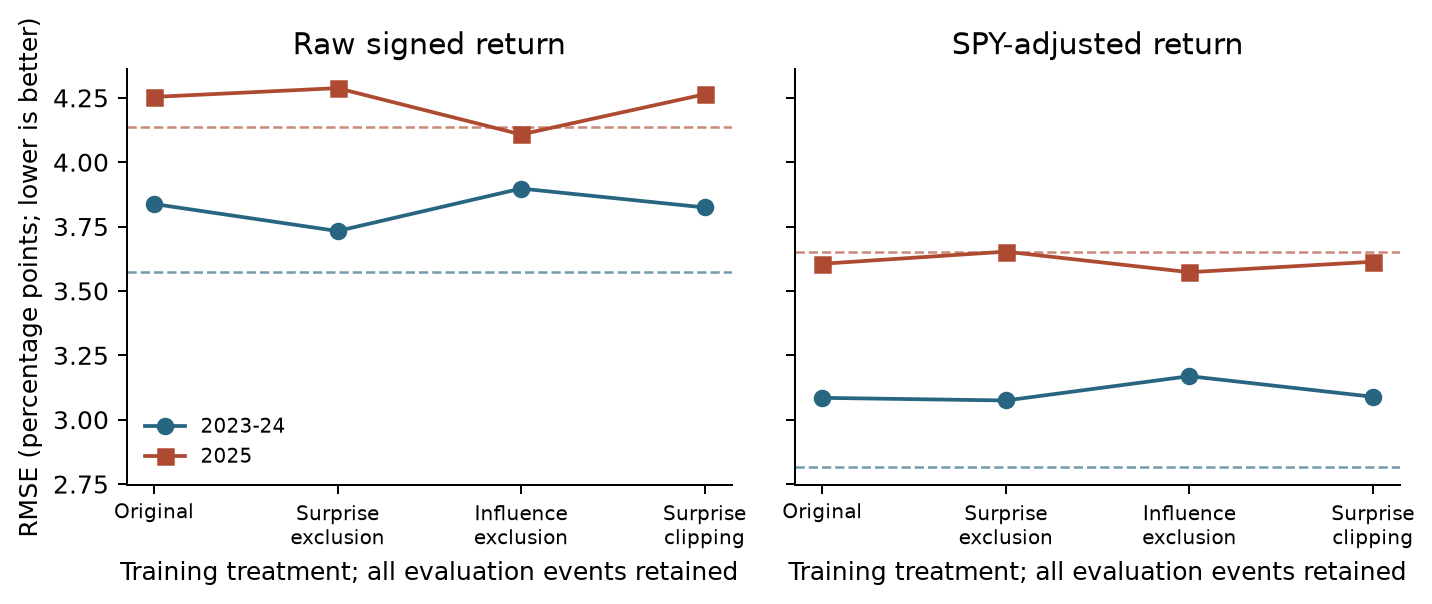

,target,split,year,model,n,mae_pp,rmse_pp,mean_error_pp,direction_accuracy
0,future_5d_return,test,2025,OLS,40,3.3160,4.2535,0.2168,0.550
1,future_5d_return,test,2025,Training mean,40,3.1607,4.1349,0.3912,0.600
2,future_5d_return,test,2025,Zero,40,3.1877,4.1522,0.5451,0.400
3,future_5d_return,validation,2023,OLS,40,3.1149,4.0578,-1.1971,0.475
4,future_5d_return,validation,2023,Training mean,40,2.7417,3.6460,-0.3685,0.425
5,future_5d_return,validation,2023,Zero,40,2.7136,3.6337,-0.2147,0.575
6,future_5d_return,validation,2024,OLS,40,2.6970,3.6038,0.3285,0.675
7,future_5d_return,validation,2024,Training mean,40,2.5827,3.4966,0.8585,0.725
8,future_5d_return,validation,2024,Zero,40,2.6419,3.5376,1.0124,0.275
9,market_adjusted_5d_return,test,2025,OLS,40,2.8762,3.6055,0.2995,0.550


,target,split,prior_volatility_group,model,n,mae_pp,rmse_pp,mean_error_pp,direction_accuracy
0,future_5d_return,test,Above training median,OLS,24,3.0400,3.7756,-0.1884,0.6250
1,future_5d_return,test,Above training median,Training mean,24,2.9947,3.8812,-0.1162,0.6667
2,future_5d_return,test,Above training median,Zero,24,3.0397,3.8796,0.0377,0.3333
3,future_5d_return,test,At or below training median,OLS,16,3.7300,4.8833,0.8246,0.4375
4,future_5d_return,test,At or below training median,Training mean,16,3.4096,4.4886,1.1523,0.5000
5,future_5d_return,test,At or below training median,Zero,16,3.4096,4.5305,1.3062,0.5000
6,future_5d_return,validation,Above training median,OLS,47,3.4484,4.4493,-1.1668,0.4894
7,future_5d_return,validation,Above training median,Training mean,47,2.9903,4.0902,-0.1931,0.5106
8,future_5d_return,validation,Above training median,Zero,47,2.9857,4.0858,-0.0392,0.4894
9,future_5d_return,validation,At or below training median,OLS,33,2.1332,2.7398,0.6089,0.6970


,target,split,quarter_omitted,n_evaluated,total_quarters,ols_rmse_pp,training_mean_rmse_pp,rmse_gain_vs_training_mean_pp
0,future_5d_return,test,2025Q1,30,4,4.3155,4.1408,-0.1747
1,future_5d_return,test,2025Q2,30,4,4.5746,4.4932,-0.0813
2,future_5d_return,test,2025Q3,30,4,3.6795,3.6604,-0.0191
3,future_5d_return,test,2025Q4,30,4,4.3908,4.2017,-0.1891
4,future_5d_return,validation,2023Q1,70,8,3.4534,3.3850,-0.0684
5,future_5d_return,validation,2023Q2,70,8,3.9741,3.7066,-0.2675
6,future_5d_return,validation,2023Q3,70,8,4.0106,3.7212,-0.2894
7,future_5d_return,validation,2023Q4,70,8,3.7560,3.4191,-0.3369
8,future_5d_return,validation,2024Q1,70,8,3.9091,3.7290,-0.1800
9,future_5d_return,validation,2024Q2,70,8,3.9866,3.6520,-0.3347


,ticker,cached_earnings_records,earliest_reported_date,latest_reported_date,pre2016_earnings_records,events_2016_2025,potential_events_2010_2025,extended_events_missing_any_earnings_value,status
0,AAPL,122,1996-04-17,2026-07-30,79,40,64,0,"Counts only; older price lookbacks/targets, la..."
1,AMZN,117,1997-07-10,2026-07-30,74,40,64,0,"Counts only; older price lookbacks/targets, la..."
2,GOOGL,88,2004-10-21,2026-07-22,45,40,64,0,"Counts only; older price lookbacks/targets, la..."
3,JNJ,122,1996-04-16,2026-07-15,79,40,64,0,"Counts only; older price lookbacks/targets, la..."
4,JPM,122,1996-04-16,2026-07-14,79,40,64,0,"Counts only; older price lookbacks/targets, la..."
5,META,58,2012-05-30,2026-07-29,15,40,55,1,"Counts only; older price lookbacks/targets, la..."
6,MSFT,122,1996-04-18,2026-07-29,79,40,64,0,"Counts only; older price lookbacks/targets, la..."
7,NVDA,110,1999-05-18,2026-08-26,67,40,64,0,"Counts only; older price lookbacks/targets, la..."
8,WMT,122,1996-05-14,2026-08-20,79,40,64,0,"Counts only; older price lookbacks/targets, la..."
9,XOM,122,1996-04-22,2026-07-31,79,40,64,0,"Counts only; older price lookbacks/targets, la..."


summary_rows                         7786
earnings_rows                      168603
earnings_first_date            2009-04-16
earnings_last_date             2021-06-14
events_with_both_eps_values        110994
events_after_2021                       0
main_model_uses_candidate           False
dtype: object

In [6]:
display(Image(filename=str(FIG / '04_baseline_comparison.png')))
display(pd.read_csv(OUT / 'holdout_residual_summary.csv').round(4))
display(pd.read_csv(OUT / 'large_surprise_events.csv'))
display(pd.read_csv(OUT / 'outlier_sensitivity.csv').round(4))
display(Image(filename=str(FIG / '05_outlier_sensitivity.png')))
display(pd.read_csv(OUT / 'performance_by_year.csv').round(4))
display(pd.read_csv(OUT / 'performance_by_volatility.csv').round(4))
display(pd.read_csv(OUT / 'leave_one_quarter_out.csv').round(4))
display(pd.read_csv(OUT / 'history_coverage_audit.csv'))
if (OUT / 'kaggle_candidate_audit.json').exists():
    candidate = json.loads((OUT / 'kaggle_candidate_audit.json').read_text())
    display(pd.Series({k: candidate[k] for k in [
        'summary_rows', 'earnings_rows', 'earnings_first_date', 'earnings_last_date',
        'events_with_both_eps_values', 'events_after_2021', 'main_model_uses_candidate']}))


Removing large-surprise training rows helps raw validation errors but worsens
2025. Influence exclusion helps 2025 but worsens validation. Clipping is also
mixed; no alternative consistently improves both periods. The original baseline
therefore remains primary. Group/quarter summaries are descriptive stability
checks, not significance tests under an independence assumption.

The history audit counts 631 candidate earnings events in 2010-2025; older
price lookbacks, lagged surprises and targets have not yet been validated.
The separately audited Kaggle version 7 earnings end in June 2021 and have
substantial missing estimates and release labels. It was not merged into the
primary dataset. See `reports/DATA_EXPANSION_REVIEW.md`.

## Preliminary answer and Milestone 3 priorities
Weak predictor associations did not produce consistent improvements over naive
forecasts. The 10-company pilot is not ready for a trading application. Repeated
companies, 597 overlapping target-window pairs and retrospectively revised data
limit conclusions. Date-only reports imperfectly separate premarket reactions.

Prioritize rolling chronological evaluation with label purging, dependence-aware
uncertainty, company/year performance, influence sensitivity, and a small set of
simple regularized models. Verify release timing and historical availability.
The inspected 2025 data must not become a fresh test after model tuning. Expansion
needs a historical ticker-selection rule and free access. Deployment needs a
tradable entry rule, spreads/costs and evidence of practical benefit.

## Questions for MTA
1. Is the first trading day after a date-only report an acceptable reaction-day convention?
2. Should raw return remain primary and SPY-adjusted return secondary?
3. How should signed forecasts inform positive-return decisions without outcome filtering?
4. What historical selection rule should guide an approximately 100-stock expansion?
5. How should rolling validation and uncertainty handle overlapping market windows?

Milestone 1 contributions are described in the supplied `ISYE 4031 Project.pdf`.
Meeting 1 notes supplied October 27 are recorded in `reports/MEETING1_FEEDBACK.md`.
Confirm each member's actual Milestone 2 work; see `reports/TEAM_CONTRIBUTIONS.md`
and `reports/MEETING2_PROGRESS_NOTE.md`. Source documentation and exact run
instructions are in `MILESTONE2_README.md`.
